# Sensores IoT: Ocupação das Salas

Em um complexo tecnológico e industrial, que está equipado com sensores ambientais IoT, se faz necessário prever em tempo real se salas técnicas e escritórios estão ocupados ou não, a fim de automatizar sistemas inteligentes de iluminação e ar-condicionado (HVAC), visando redução de custos com energia.

A variável alvo do projeto é binária: `Occupancy` = 1 (ambiente ocupado / ativo) e `Occupancy` = 0 (ambiente desocupado / inativo).

**Base de Dados**: Occupancy Detection Dataset (UCI Machine Learning Repository / Kaggle), composta pelas seguintes variáveis ambientais:
- `Temperature`: Temperatura do ambiente em graus Celsius (°C).
- `Humidity`: Umidade relativa do ar (%).
- `Light`: Nível de luminosidade medido pelo sensor (Lux).
- `CO2`: Concentração de dióxido de carbono no ar (ppm).
- `HumidityRatio`: Taxa derivada de umidade específica e temperatura.
- `Occupancy` (Variável Alvo): Indicador binário de presença (0 = Desocupado, 1 = Ocupado).


**Objetivo do Projeto:**

Comparar KNN e Árvore de Decisão e escolher o modelo para a automação predial.


**Fases do Projeto:**
- Fase 1: Análise Exploratória (EDA)
- Fase 2: Limpeza e Tratamento de Dados (Data Prep)
- Fase 3: Feature Engineering
- Fase 4: Divisão e Balanceamento dos Dados
- Fase 5: Escalonamento de Variáveis (StandardScaler)
- Fase 6: Ajuste de Parâmetros e Combate ao Overfitting
- Fase 7: Avaliação da Acurácia e Veredito Final



### Importação das bibliotecas

Importar as bibliotecas utilizadas em todo o projeto:

- **pandas** e **numpy**: leitura e manipulação dos dados.
- **matplotlib** e **seaborn**: criação dos gráficos da análise exploratória.
- **scikit-learn** (Machine Learning):
  - `train_test_split`: divisão da base em treino e teste;
  - `StandardScaler`: padronização da escala das variáveis para o KNN;
  - `KNeighborsClassifier` e `DecisionTreeClassifier`: os dois modelos comparados;
  - `accuracy_score`, `classification_report` e `confusion_matrix`: avaliação dos modelos.
- **os**, **zipfile** e **urllib.request**: download e extração da base de dados.

Também são definidas as configurações visuais padrão dos gráficos (fundo sem grade e tamanho da figura).

In [1]:
# Bibliotecas
import os
import zipfile
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

# Configurações visuais para os gráficos
sns.set_theme(style="white")
plt.rcParams["figure.figsize"] = (10, 5)

### Pasta para salvar os gráficos

Definir a pasta onde os principais gráficos são salvos, para uso na documentação do projeto.

In [2]:
pasta_figuras = "../reports/figures"
os.makedirs(pasta_figuras, exist_ok=True)

## Fase 1: Análise Exploratória (EDA)

Antes de treinar qualquer modelo, é preciso conhecer a base: quantas linhas e colunas existem, quais são os tipos de dados, como os valores se distribuem e como as variáveis se relacionam com a ocupação da sala. Essa etapa orienta todas as decisões das fases seguintes.

### Carregamento da base de dados

**Fonte:** Occupancy Detection Dataset, disponível no UCI Machine Learning Repository.

A base é baixada diretamente do repositório da UCI, em vez da versão disponibilizada em planilha online. A versão em planilha apresentou problemas de formatação: ao ser importada com configuração regional em português, o ponto decimal foi interpretado como separador de milhar, e valores como `0.0047` em `HumidityRatio` passaram a aparecer como números inteiros muito grandes. O arquivo original da UCI não passa por nenhuma planilha e preserva os valores corretos.

O arquivo baixado contém três partes da mesma coleta (`datatraining.txt`, `datatest.txt` e `datatest2.txt`). As três são lidas e unidas em um único DataFrame, formando a base completa, que é salva em `data/occupancy_completo.csv`.

O download acontece apenas na primeira execução: se o arquivo já existir na pasta `data/`, o código pula direto para a leitura. Todos os caminhos são relativos à pasta do notebook, para que o projeto rode em qualquer computador.

In [3]:
caminho_csv = "../data/occupancy_completo.csv"

# Baixar e extrair a base da UCI apenas se o arquivo final ainda não existir
if not os.path.exists(caminho_csv):
    url_uci = "https://archive.ics.uci.edu/ml/machine-learning-databases/00357/occupancy_data.zip"
    zip_path = "../data/occupancy_data.zip"
    urllib.request.urlretrieve(url_uci, zip_path)

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall("../data/raw")

    # Ler as três partes da base
    df_treino = pd.read_csv("../data/raw/datatraining.txt")
    df_teste1 = pd.read_csv("../data/raw/datatest.txt")
    df_teste2 = pd.read_csv("../data/raw/datatest2.txt")

    # Unir as três partes em um único DataFrame
    df_completo = pd.concat([df_treino, df_teste1, df_teste2], ignore_index=True)

    # Salvar a base completa
    df_completo.to_csv(caminho_csv, index=False)

# Carregar a base completa
df = pd.read_csv(caminho_csv)
print("Base de dados carregada com sucesso!")

Base de dados carregada com sucesso!


In [4]:
df.head(10)

,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,2015-02-04 17:51:00,23.180,27.2720,426.0,721.250000,0.004793,1
1,2015-02-04 17:51:59,23.150,27.2675,429.5,714.000000,0.004783,1
2,2015-02-04 17:53:00,23.150,27.2450,426.0,713.500000,0.004779,1
3,2015-02-04 17:54:00,23.150,27.2000,426.0,708.250000,0.004772,1
4,2015-02-04 17:55:00,23.100,27.2000,426.0,704.500000,0.004757,1
5,2015-02-04 17:55:59,23.100,27.2000,419.0,701.000000,0.004757,1
6,2015-02-04 17:57:00,23.100,27.2000,419.0,701.666667,0.004757,1
7,2015-02-04 17:57:59,23.100,27.2000,419.0,699.000000,0.004757,1
8,2015-02-04 17:58:59,23.100,27.2000,419.0,689.333333,0.004757,1
9,2015-02-04 18:00:00,23.075,27.1750,419.0,688.000000,0.004745,1


As primeiras linhas confirmam que a base foi carregada corretamente, com sete colunas: a data e hora da medição (`date`), as cinco variáveis dos sensores (`Temperature`, `Humidity`, `Light`, `CO2` e `HumidityRatio`) e a variável alvo `Occupancy`.

Os valores numéricos aparecem com ponto decimal e na escala esperada (por exemplo, `HumidityRatio` com valores próximos de 0,005), sem a distorção observada na versão em planilha.

Os arquivos `.txt` da UCI trazem, no início de cada linha, um número de registro sem nome no cabeçalho. Ao ler os arquivos, o pandas interpretou essa coluna como índice, e não como dado. Na união das três partes, o parâmetro `ignore_index=True` renumerou as linhas em uma sequência única, e o `index=False` impediu que esse índice fosse gravado no arquivo final. Por isso, a base final contém apenas as colunas de interesse.

### Dimensões da base

Verificar quantas linhas (medições) e quantas colunas (variáveis) a base possui. O tamanho da base ajuda a avaliar se há dados suficientes para treinar e testar os modelos.

In [5]:
df.shape

(20560, 7)

A base possui **20.560 linhas** (medições dos sensores) e **7 colunas**. É um volume adequado para treinar e testar modelos de classificação, mesmo após reservar 20% dos dados para o teste.

### Tipos de dados e valores não nulos

Verificar o tipo de cada coluna e a quantidade de valores preenchidos. Os modelos de Machine Learning trabalham apenas com números, então é preciso confirmar que as variáveis dos sensores foram lidas como numéricas e identificar colunas que exigem algum tratamento antes da modelagem. A contagem de valores não nulos também dá uma primeira indicação sobre a existência de dados ausentes, que serão tratados na Fase 2.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20560 entries, 0 to 20559
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           20560 non-null  str    
 1   Temperature    20560 non-null  float64
 2   Humidity       20560 non-null  float64
 3   Light          20560 non-null  float64
 4   CO2            20560 non-null  float64
 5   HumidityRatio  20560 non-null  float64
 6   Occupancy      20560 non-null  int64  
dtypes: float64(5), int64(1), str(1)
memory usage: 1.1 MB


Todas as colunas possuem 20.560 valores preenchidos, ou seja, **não há dados ausentes** na base original. Essa verificação será repetida na Fase 2, com o tratamento adequado.

As cinco variáveis dos sensores (`Temperature`, `Humidity`, `Light`, `CO2` e `HumidityRatio`) foram lidas como números decimais (`float64`), e a variável alvo `Occupancy` como número inteiro (`int64`), o que confirma a leitura correta dos dados.

A única coluna que não é numérica é `date`, lida como texto (`str`). Ela será tratada a seguir.

### Resumo estatístico

Calcular as principais medidas estatísticas das colunas numéricas: contagem, média, desvio padrão, valores mínimo e máximo e quartis (25%, 50% e 75%). Esse resumo mostra a escala de cada sensor, ajuda a identificar possíveis valores extremos e permite comparar média e mediana (50%) para avaliar a simetria das distribuições.

In [7]:
df.describe()

,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
count,20560.000000,20560.000000,20560.000000,20560.000000,20560.000000,20560.000000
mean,20.906212,27.655925,130.756622,690.553276,0.004228,0.231031
std,1.055315,4.982154,210.430875,311.201281,0.000768,0.421503
min,19.000000,16.745000,0.000000,412.750000,0.002674,0.000000
25%,20.200000,24.500000,0.000000,460.000000,0.003719,0.000000
50%,20.700000,27.290000,0.000000,565.416667,0.004292,0.000000
75%,21.525000,31.290000,301.000000,804.666667,0.004832,0.000000
max,24.408333,39.500000,1697.250000,2076.500000,0.006476,1.000000


Principais observações do resumo estatístico:

- **`Temperature`** varia pouco: de 19,0 °C a 24,4 °C, com desvio padrão de cerca de 1 °C. Média (20,91) e mediana (20,70) são próximas, indicando uma distribuição quase simétrica.
- **`Humidity`** varia de 16,7% a 39,5%, também com média (27,66) e mediana (27,29) próximas.
- **`Light`** apresenta o comportamento mais marcante: a **mediana é 0**, o que significa que em pelo menos metade das medições a luz estava apagada. Já a média (130,76) e o máximo (1.697,25 Lux) são muito maiores, indicando uma distribuição fortemente assimétrica, com valores altos concentrados em parte dos registros.
- **`CO2`** varia de 412,75 a 2.076,5 ppm, com média (690,55) bem acima da mediana (565,42), o que também indica assimetria à direita: a maior parte das medições tem CO2 mais baixo, e alguns momentos registram valores altos.
- **`HumidityRatio`** tem valores muito pequenos (em torno de 0,004), em uma escala completamente diferente das demais variáveis.
- **`Occupancy`** tem média de 0,231. Como a variável só assume 0 ou 1, isso indica que **cerca de 23% das medições correspondem a salas ocupadas** e 77% a salas vazias. As classes são **desbalanceadas**, o que exige atenção: um modelo que sempre previsse "vazio" já acertaria cerca de 77% dos casos (o Paradoxo da Acurácia). Por isso, a divisão entre treino e teste será feita com estratificação (Fase 4).

A grande diferença de escala entre os sensores (`Light` chega a quase 1.700, enquanto `HumidityRatio` não passa de 0,007) reforça a necessidade de padronizar as variáveis para o KNN, que se baseia em distâncias (Fase 5).

### Tratamento da coluna `date`

A coluna `date` registra a data e a hora de cada medição. Ela será **descartada antes da modelagem** pelos seguintes motivos:

- É uma coluna de texto, e os modelos KNN e Árvore de Decisão trabalham apenas com números.
- Cada valor é praticamente único (um registro por minuto), então o modelo não conseguiria aprender um padrão a partir dela.
- O objetivo do sistema é prever a ocupação **a partir das condições do ambiente medidas pelos sensores**, e não a partir do momento da medição.

Uma melhoria possível seria extrair informações da data, como a hora do dia ou o dia da semana, que podem ter relação com a ocupação. Essa possibilidade fica registrada como melhoria futura.

In [8]:
df = df.drop(columns="date")
df.shape

(20560, 6)

Após o descarte de `date`, a base passa a ter 6 colunas: as cinco variáveis dos sensores e a variável alvo `Occupancy`, todas numéricas.

### Distribuição das variáveis preditoras

Plotar o histograma de cada variável dos sensores para observar como os valores se distribuem: se são simétricos, assimétricos, concentrados em uma faixa ou com valores extremos. Essa leitura ajuda a escolher entre média e mediana no tratamento de dados ausentes (Fase 2).

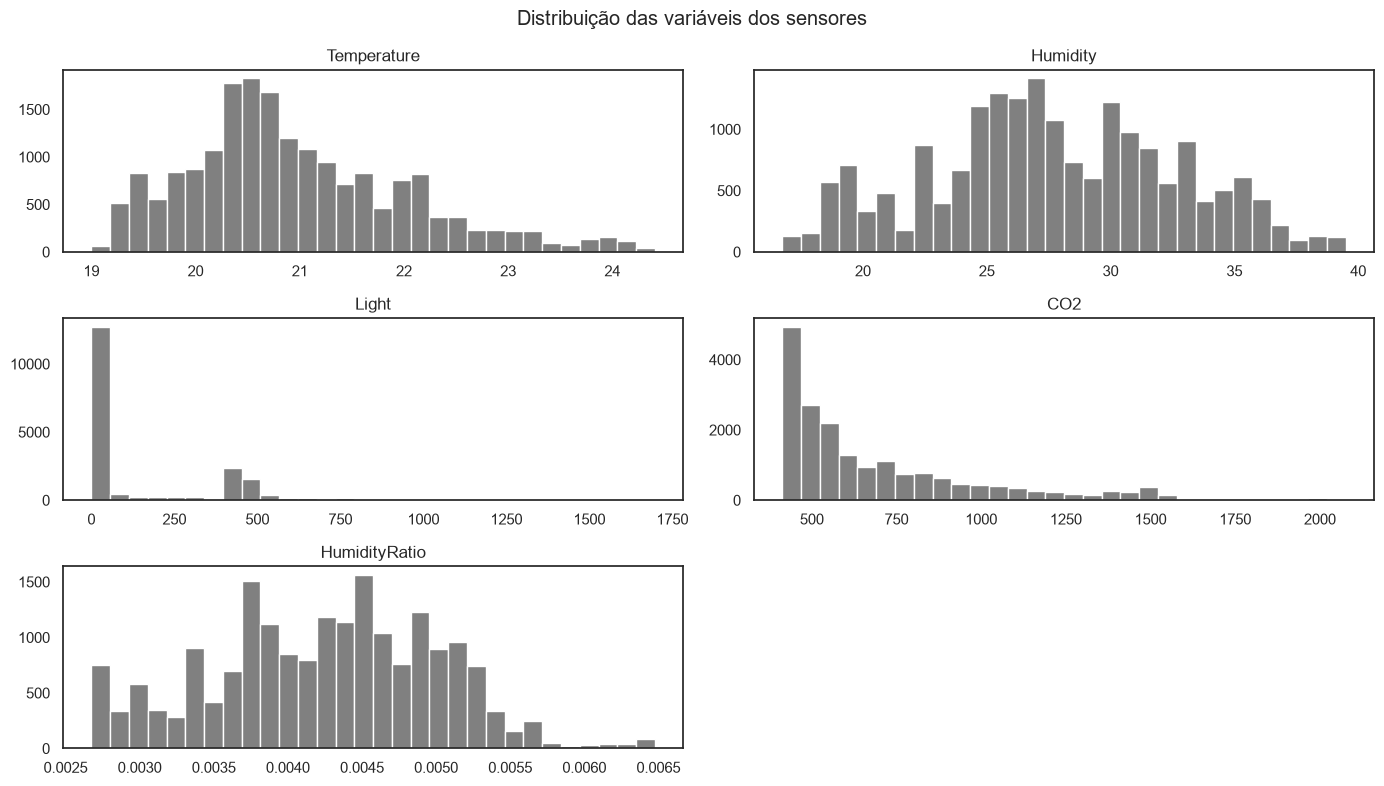

In [45]:
colunas_sensores = ["Temperature", "Humidity", "Light", "CO2", "HumidityRatio"]

df[colunas_sensores].hist(bins=30, figsize=(14, 8), color="gray", edgecolor="white", grid=False)
plt.suptitle("Distribuição das variáveis dos sensores")
plt.tight_layout()
plt.savefig(f"{pasta_figuras}/histogramas_sensores.png", dpi=150, bbox_inches="tight")
plt.show()

- **`Light`** tem uma distribuição com dois grupos bem separados: uma grande concentração em 0 (luz apagada) e um segundo grupo entre aproximadamente 400 e 500 Lux, que corresponde à iluminação artificial acesa. Poucos registros ficam fora desses dois grupos, e os valores mais altos, que chegam perto de 1.700 Lux, podem representar luz solar intensa.
- **`CO2`** é fortemente assimétrico à direita: a maior parte das medições está entre 400 e 600 ppm, com uma cauda longa até cerca de 2.000 ppm, que reflete momentos de maior presença de pessoas.
- **`Temperature`** se concentra entre 20 °C e 21 °C, com uma leve cauda à direita.
- **`Humidity`** e **`HumidityRatio`** têm distribuições mais espalhadas e irregulares, com vários picos, o que é coerente com medições feitas em dias diferentes.

### Proporção das classes da variável alvo

Verificar a proporção de medições com sala ocupada (1) e desocupada (0). O equilíbrio entre as classes influencia a escolha da métrica de avaliação e a forma de dividir os dados em treino e teste.

In [10]:
proporcao = df["Occupancy"].value_counts(normalize=True) * 100
proporcao

Occupancy
0    76.896887
1    23.103113
Name: proportion, dtype: float64

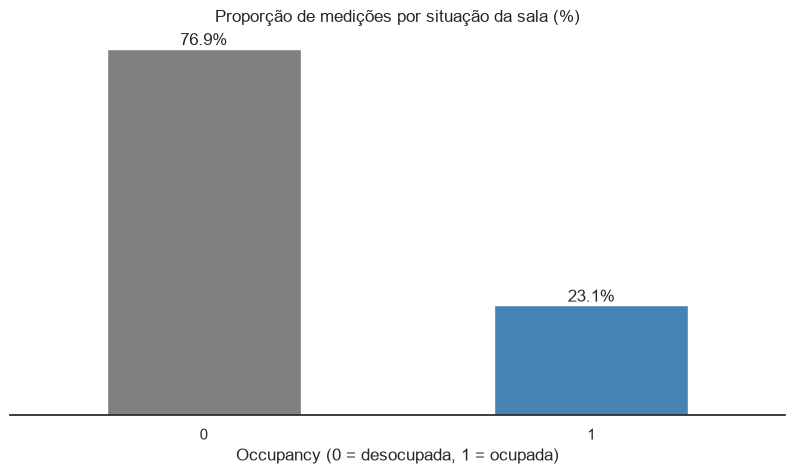

In [11]:
ax = proporcao.plot(kind="bar", color=["gray", "steelblue"])
ax.set_title("Proporção de medições por situação da sala (%)")
ax.set_xlabel("Occupancy (0 = desocupada, 1 = ocupada)")
ax.set_ylabel("")
ax.set_yticks([])
ax.spines[["top", "right", "left"]].set_visible(False)
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.xticks(rotation=0)
plt.show()

**76,9%** das medições correspondem a salas desocupadas e **23,1%** a salas ocupadas. As classes são desbalanceadas: um modelo que respondesse sempre "desocupada" teria 76,9% de acurácia sem aprender nada. Esse valor serve como **referência mínima**: os modelos só têm valor real se superarem esse patamar com folga.

### Correlação entre as variáveis

Calcular a correlação de Pearson entre todas as variáveis e exibir o resultado em um mapa de calor. A correlação varia de -1 a 1: valores próximos de 1 indicam que duas variáveis crescem juntas, próximos de -1 que uma cresce enquanto a outra diminui, e próximos de 0 que não há relação linear. A linha de `Occupancy` mostra quais sensores têm maior relação com a ocupação da sala.

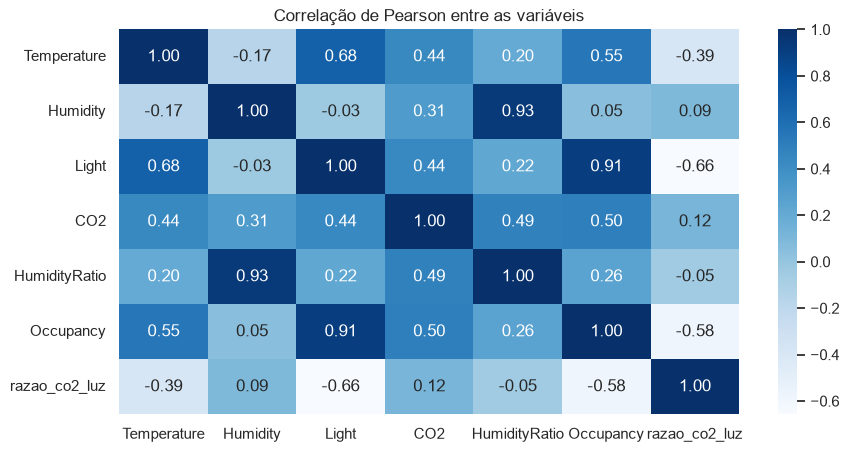

In [43]:
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="Blues")
plt.title("Correlação de Pearson entre as variáveis")
plt.savefig(f"{pasta_figuras}/correlacao.png", dpi=150, bbox_inches="tight")
plt.show()

Correlação de cada sensor com `Occupancy`, da mais forte para a mais fraca:

| Sensor | Correlação |
|---|---|
| `Light` | 0,91 |
| `Temperature` | 0,56 |
| `CO2` | 0,50 |
| `HumidityRatio` | 0,26 |
| `Humidity` | 0,05 |

Também chama atenção a correlação de **0,93 entre `Humidity` e `HumidityRatio`**: as duas variáveis carregam praticamente a mesma informação, o que é esperado, já que `HumidityRatio` é calculada a partir da umidade e da temperatura.

### Análise exploratória: principais conclusões e estratégia de modelagem

**1. A luminosidade é o sinal mais forte de ocupação.** `Light` tem correlação de 0,91 com `Occupancy`, e seu histograma mostra dois grupos bem definidos: luz apagada (0 Lux) e luz acesa (entre 400 e 500 Lux). Isso faz sentido no contexto predial: quando há pessoas na sala, a iluminação costuma estar ligada. É provável que os dois modelos dependam fortemente dessa variável e alcancem acurácias altas.

**2. CO2 e temperatura complementam a informação.** `CO2` (0,50) e `Temperature` (0,56) têm correlação moderada com a ocupação. A presença de pessoas aumenta o CO2 pela respiração e eleva a temperatura do ambiente. São variáveis importantes para os casos em que a luz sozinha não basta, como uma sala vazia com luz esquecida acesa ou uma sala ocupada iluminada apenas pela luz natural.

**3. A umidade relativa quase não se relaciona com a ocupação.** `Humidity` tem correlação de apenas 0,05 com `Occupancy`. Além disso, ela é altamente correlacionada com `HumidityRatio` (0,93), ou seja, as duas repetem a mesma informação. Neste projeto, todas as variáveis serão mantidas, conforme o enunciado, mas a redundância fica registrada como ponto de atenção.

**Como essas observações direcionam a modelagem:**

- **Métrica e referência:** com 76,9% das medições na classe "desocupada", a acurácia precisa ser comparada com esse patamar. Um modelo com 80% de acurácia, por exemplo, seria apenas um pouco melhor do que sempre responder "desocupada".
- **Divisão estratificada (Fase 4):** o desbalanceamento exige `stratify=y`, para que treino e teste mantenham a mesma proporção de salas ocupadas e vazias.
- **Escala (Fase 5):** os sensores têm escalas muito diferentes (`Light` vai de 0 a quase 1.700, `HumidityRatio` fica abaixo de 0,007). Sem padronização, o KNN, que calcula distâncias, seria dominado por `Light` e `CO2`. A Árvore de Decisão não sofre esse efeito.
- **Assimetria (Fase 2):** `Light` e `CO2` são fortemente assimétricas, o que indica a **mediana** como medida mais adequada para uma eventual imputação de valores ausentes.

## Fase 2: Limpeza e Tratamento de Dados (Data Prep)

Dados inconsistentes geram modelos ruins (*Garbage In, Garbage Out*). Nesta fase, a base é preparada para a modelagem em três etapas: remoção de linhas duplicadas, verificação e tratamento de dados ausentes e identificação de valores discrepantes (outliers).

### Linhas duplicadas

Verificar se existem linhas exatamente iguais na base. Registros repetidos fazem o modelo "aprender" o mesmo exemplo várias vezes, dando peso exagerado a algumas situações. Além disso, se uma linha estiver no treino e sua cópia no teste, o modelo seria avaliado com um exemplo que já viu, o que infla a acurácia.

Como a coluna `date` foi descartada na Fase 1, medições feitas em horários diferentes, mas com os mesmos valores em todos os sensores, passam a ser consideradas duplicadas.

In [13]:
df.duplicated().sum()

np.int64(1441)

Foram encontradas **1.441 linhas duplicadas**. Elas correspondem a períodos de estabilidade do ambiente, em que os sensores registraram exatamente os mesmos valores em medições consecutivas, como salas vazias, com luz apagada e temperatura constante. Sem a coluna `date`, esses registros se tornam idênticos e são removidos, mantendo apenas a primeira ocorrência.

In [14]:
df = df.drop_duplicates()
df.shape

(19119, 6)

Após a remoção, a base passa a ter **19.119 linhas** e 6 colunas.

### Dados ausentes

Verificar a quantidade de valores ausentes (NaN) em cada coluna. Modelos como KNN e Árvore de Decisão do scikit-learn não aceitam valores ausentes, por isso eles precisam ser tratados antes do treinamento.

In [15]:
df.isnull().sum()

Temperature      0
Humidity         0
Light            0
CO2              0
HumidityRatio    0
Occupancy        0
dtype: int64

Nenhuma coluna possui valores ausentes. Como o enunciado prevê, para validar a etapa de tratamento do pipeline, valores ausentes serão **simulados** em uma cópia da base, e a imputação será aplicada nessa cópia. A base original, que será usada nos modelos, permanece com os valores reais dos sensores.

### Simulação de dados ausentes

Criar uma cópia da base e substituir 200 valores de `Temperature` e 200 valores de `CO2` por NaN, escolhidos aleatoriamente com semente fixa (para que o resultado seja sempre o mesmo). As duas colunas foram escolhidas por terem distribuições diferentes, o que permite comparar os dois métodos de imputação.

In [16]:
df_nulos = df.copy()

linhas_temp = df_nulos.sample(n=200, random_state=42).index
df_nulos.loc[linhas_temp, "Temperature"] = np.nan

linhas_co2 = df_nulos.sample(n=200, random_state=7).index
df_nulos.loc[linhas_co2, "CO2"] = np.nan

df_nulos.isnull().sum()

Temperature      200
Humidity           0
Light              0
CO2              200
HumidityRatio      0
Occupancy          0
dtype: int64

A cópia `df_nulos` passa a ter 200 valores ausentes em `Temperature` e 200 em `CO2`, enquanto as demais colunas permanecem completas. Como foram usadas sementes diferentes (42 e 7), os valores ausentes estão em linhas diferentes nas duas colunas, simulando falhas independentes em cada sensor.

### Escolha entre média e mediana

Comparar a média e a mediana das duas colunas para decidir o método de imputação. Quando a distribuição é simétrica, média e mediana são próximas e a média representa bem o valor típico. Quando é assimétrica, a média é "puxada" pelos valores extremos, e a mediana passa a representar melhor o centro dos dados.

In [17]:
df_nulos[["Temperature", "CO2"]].agg(["mean", "median"])

,Temperature,CO2
mean,20.964926,703.366188
median,20.790000,574.250000


**Justificativa da escolha:**

- **`Temperature`**: média de 20,96 °C e mediana de 20,79 °C, valores muito próximos. Isso confirma o que o histograma mostrou na Fase 1: uma distribuição quase simétrica, sem valores extremos que distorçam a média. Nesse caso, a **média** é uma boa representante do valor típico e foi escolhida para a imputação.

- **`CO2`**: média de 703,37 ppm e mediana de 574,25 ppm, uma diferença grande. O histograma mostrou uma distribuição fortemente assimétrica à direita, com uma cauda longa de valores altos (momentos de sala cheia). Esses valores extremos "puxam" a média para cima, e preencher os ausentes com ela criaria medições de CO2 mais altas do que o normal. A **mediana**, que não é afetada pelos extremos, representa melhor o valor típico e foi escolhida para a imputação.

### Imputação dos valores ausentes

Preencher os valores ausentes de `Temperature` com a **média** e os de `CO2` com a **mediana**, conforme a análise de simetria.

In [18]:
df_nulos["Temperature"] = df_nulos["Temperature"].fillna(df_nulos["Temperature"].mean())
df_nulos["CO2"] = df_nulos["CO2"].fillna(df_nulos["CO2"].median())
df_nulos.isnull().sum()

Temperature      0
Humidity         0
Light            0
CO2              0
HumidityRatio    0
Occupancy        0
dtype: int64

Após a imputação, nenhuma coluna da cópia possui valores ausentes, o que confirma que o tratamento funcionou. A base original `df` não foi alterada e segue para as próximas etapas com os valores reais dos sensores.

### Valores discrepantes (outliers)

Gerar um boxplot para cada variável dos sensores. O boxplot mostra a mediana (linha central), o intervalo onde estão 50% dos dados (a caixa) e os valores muito afastados do restante, marcados como pontos isolados (possíveis outliers). Como os sensores têm escalas muito diferentes, cada variável é exibida em um gráfico separado.

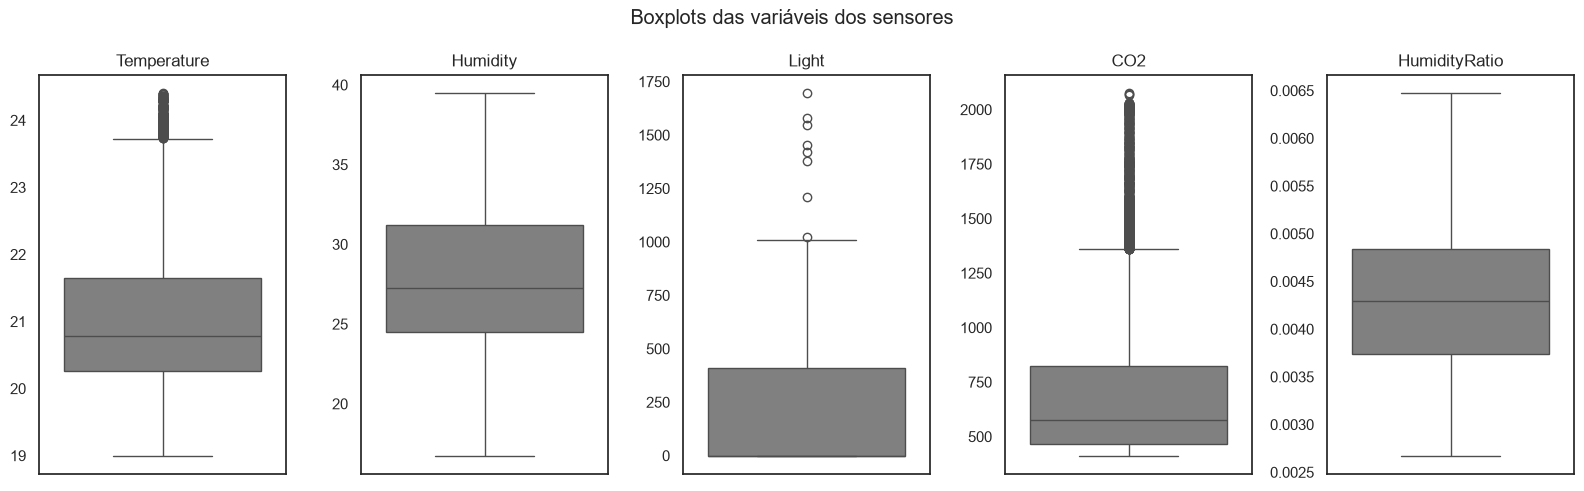

In [44]:
fig, eixos = plt.subplots(1, 5, figsize=(16, 5))

for eixo, coluna in zip(eixos, colunas_sensores):
    sns.boxplot(y=df[coluna], ax=eixo, color="gray")
    eixo.set_title(coluna)
    eixo.set_ylabel("")

plt.suptitle("Boxplots das variáveis dos sensores")
plt.tight_layout()
plt.savefig(f"{pasta_figuras}/boxplots_sensores.png", dpi=150, bbox_inches="tight")
plt.show()



**Análise dos outliers:**

- **`CO2`** apresenta a maior quantidade de pontos acima do limite superior do boxplot, chegando a cerca de 2.000 ppm.
- **`Temperature`** apresenta alguns valores acima de aproximadamente 23,7 °C.
- **`Light`** apresenta poucos valores isolados acima de 1.000 Lux, chegando a cerca de 1.700 Lux. A mediana próxima de zero, já observada na Fase 1, aparece aqui como a linha central encostada na base da caixa.
- **`Humidity`** e **`HumidityRatio`** não apresentam outliers.

**Decisão: os outliers serão mantidos.** Eles não são erros de medição, e sim situações reais do ambiente:

- CO2 e temperatura elevados acontecem quando há várias pessoas na sala, pela respiração e pelo calor do corpo. Ou seja, esses valores carregam justamente a informação que os modelos precisam para identificar a ocupação.
- Luminosidade muito alta é compatível com a entrada de luz solar direta em alguns horários.

Remover esses registros apagaria exemplos importantes de salas ocupadas, que já são a classe minoritária (23,1% das medições). Além disso, a Árvore de Decisão é pouco sensível a valores extremos, e para o KNN a padronização da Fase 5 reduz o efeito das diferenças de escala.

## Fase 3: Feature Engineering

*Feature Engineering* é a criação de novas variáveis a partir das existentes, com o objetivo de destacar padrões que ajudem o modelo. A própria base já traz um exemplo: `HumidityRatio` é calculada a partir da umidade e da temperatura, com base em conhecimento de física do ar.

Nesta fase, é criada a variável **`razao_co2_luz`**, que relaciona a concentração de CO2 com a luminosidade:

`razao_co2_luz = CO2 / (Light + 1)`

**Por que essa combinação:** a análise exploratória mostrou que `Light` e `CO2` são os sensores mais relacionados à ocupação. A razão entre eles resume a situação do ambiente em um único número: com a luz apagada, o valor fica alto (próximo do próprio CO2); com a luz acesa, ele cai bastante.

**Por que o `+ 1`:** em mais da metade das medições, `Light` é igual a zero. Dividir por zero geraria valores infinitos e inválidos. Somar 1 ao denominador evita esse problema sem alterar de forma relevante os valores em que a luz está acesa.

**Sobre vazamento de dados:** o cálculo usa apenas valores da própria linha, sem nenhuma estatística do conjunto (como média ou desvio padrão). Por isso, pode ser feito antes da divisão entre treino e teste sem risco de vazamento.

### Verificação de nulos antes do cálculo

Confirmar que `CO2` e `Light` não possuem valores ausentes, já que qualquer operação com NaN resulta em NaN.

In [20]:
df[["CO2", "Light"]].isnull().sum()

CO2      0
Light    0
dtype: int64

Nenhuma das duas colunas possui valores ausentes, então o cálculo pode ser feito com segurança.

### Criação da variável `razao_co2_luz`

In [21]:
df["razao_co2_luz"] = df["CO2"] / (df["Light"] + 1)
df.head()

,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy,razao_co2_luz
0,23.18,27.2720,426.0,721.25,0.004793,1,1.689110
1,23.15,27.2675,429.5,714.00,0.004783,1,1.658537
2,23.15,27.2450,426.0,713.50,0.004779,1,1.670960
3,23.15,27.2000,426.0,708.25,0.004772,1,1.658665
4,23.10,27.2000,426.0,704.50,0.004757,1,1.649883


A nova coluna foi adicionada ao final da base. Nas primeiras linhas, com a sala ocupada e a luz acesa (cerca de 426 Lux), a razão fica em torno de 1,6 a 1,7.

### Validação da nova variável

Verificar se a nova coluna possui valores ausentes ou infinitos e observar seu resumo estatístico.

In [22]:
df["razao_co2_luz"].isnull().sum()

np.int64(0)

In [23]:
np.isinf(df["razao_co2_luz"]).sum()

np.int64(0)

In [24]:
df["razao_co2_luz"].describe()

count    19119.000000
mean       371.428659
std        366.581667
min          0.294270
25%          2.814018
50%        441.666667
75%        548.000000
max       2076.500000
Name: razao_co2_luz, dtype: float64

A nova variável não possui valores ausentes nem infinitos, o que confirma que o `+ 1` no denominador evitou a divisão por zero.

O resumo estatístico mostra dois comportamentos bem distintos:

- **25% das medições têm razão de até 2,81**: são os momentos com luz acesa, em que o CO2 é dividido por um valor alto de luminosidade.
- **A mediana é 441,67 e o máximo é 2.076,5**: com a luz apagada, a razão fica praticamente igual ao próprio valor de CO2, já que a divisão é feita por 1. O valor máximo coincide com o maior CO2 registrado na base.

Essa separação em dois grupos reflete o mesmo padrão de luz acesa e apagada observado no histograma de `Light` na Fase 1.

### Relação da nova variável com a ocupação

Calcular a correlação de `razao_co2_luz` com `Occupancy` para avaliar se a nova variável carrega informação útil para os modelos.

In [25]:
df["razao_co2_luz"].corr(df["Occupancy"])

np.float64(-0.5788465672764773)

A correlação de `razao_co2_luz` com `Occupancy` é de **-0,58**. O sinal negativo confirma a lógica da variável: quando a sala está ocupada, a luz costuma estar acesa e a razão cai; quando está vazia, a razão sobe.

Em valor absoluto, essa correlação é maior do que a de `CO2` isolado (0,50, calculada na Fase 1), o que indica que a combinação dos dois sensores trouxe informação adicional e justifica a inclusão da nova variável nos modelos.

## Fase 4: Divisão e Balanceamento dos Dados

Para avaliar se um modelo realmente aprendeu, ele precisa ser testado com dados que nunca viu durante o treinamento. Por isso, a base é dividida em dois conjuntos: **treino (80%)**, usado para o modelo aprender os padrões, e **teste (20%)**, que simula dados novos do mundo real.

### Separação entre variáveis preditoras (X) e variável alvo (y)

- **X**: as variáveis que o modelo usa para fazer a previsão (os cinco sensores e a variável `razao_co2_luz`).
- **y**: a resposta que o modelo deve aprender a prever (`Occupancy`).

In [26]:
X = df.drop(columns="Occupancy")
y = df["Occupancy"]

In [27]:
print(X.shape)
print(y.shape)

(19119, 6)
(19119,)


X ficou com 19.119 linhas e 6 colunas (as variáveis preditoras), e y com as mesmas 19.119 linhas (a variável alvo).

### Divisão em treino e teste

A divisão usa:
- `test_size=0.2`: 20% dos dados para teste e 80% para treino;
- `stratify=y`: mantém a mesma proporção de salas ocupadas e vazias nos dois conjuntos. Como as classes são desbalanceadas (cerca de 25% de ocupadas), uma divisão totalmente aleatória poderia, por acaso, deixar o teste com proporções diferentes do treino;
- `random_state=42`: semente fixa, para que a divisão seja sempre a mesma e o resultado possa ser reproduzido.

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

In [29]:
print(X_train.shape, X_test.shape)

(15295, 6) (3824, 6)


O conjunto de treino ficou com **15.295 linhas** e o de teste com **3.824 linhas**, ambos com as 6 variáveis preditoras, o que corresponde à divisão de 80% e 20% das 19.119 medições.

### Verificação da proporção das classes

Conferir se a proporção de salas ocupadas e vazias ficou igual no treino e no teste.

In [30]:
y_train.value_counts(normalize=True) * 100

Occupancy
0    75.168356
1    24.831644
Name: proportion, dtype: float64

In [31]:
y_test.value_counts(normalize=True) * 100

Occupancy
0    75.183054
1    24.816946
Name: proportion, dtype: float64

A proporção das classes ficou praticamente idêntica nos dois conjuntos: **75,17% de salas vazias e 24,83% de ocupadas no treino**, e **75,18% e 24,82% no teste**. Isso confirma que o `stratify=y` funcionou.

Essas proporções são um pouco diferentes das observadas na Fase 1 (76,9% e 23,1%). A diferença vem da remoção das duplicadas na Fase 2: a maioria delas correspondia a períodos de sala vazia, com os sensores estáveis, o que reduziu um pouco o peso dessa classe. Com isso, a referência mínima para avaliar os modelos passa a ser de **cerca de 75%**: é a acurácia que um modelo teria respondendo sempre "sala vazia".

### Por que dividir antes de qualquer transformação (Data Leakage)

*Data Leakage* (vazamento de dados) acontece quando informações do conjunto de teste "vazam" para o treinamento. O modelo passa a ter acesso, mesmo que indiretamente, a dados que deveriam ser totalmente novos, e a avaliação fica otimista demais: o resultado no teste parece ótimo, mas não se repete quando o sistema recebe dados reais.

O `StandardScaler` calcula a **média e o desvio padrão** de cada coluna para padronizar os dados. Se a padronização fosse feita **antes** da divisão, esses valores seriam calculados com a base inteira, incluindo as medições do teste. Ou seja, o treinamento já carregaria um "resumo" dos dados de teste.

Dividindo **antes**, a média e o desvio padrão são calculados **apenas com o treino**, e o teste é transformado com esses mesmos valores, exatamente como aconteceria com uma nova medição chegando dos sensores em tempo real: o sistema só conhece o passado, nunca o futuro.

Uma analogia: é como um aluno que estuda pela própria prova que vai fazer. Ele tira nota alta, mas a nota não mostra o quanto ele realmente aprendeu.

## Fase 5: Escalonamento de Variáveis (StandardScaler)

O `StandardScaler` transforma cada variável para que ela tenha **média 0 e desvio padrão 1**. Assim, todos os sensores passam a ter a mesma escala, independentemente da unidade original (Lux, ppm, °C ou %).

### Padronização dos dados do KNN

O KNN classifica uma medição olhando para as medições mais parecidas com ela, e mede essa semelhança pela **distância** entre os valores. Sem padronização, variáveis com números grandes dominam a distância: uma diferença de 300 Lux em `Light` pesaria muito mais do que uma diferença de 0,001 em `HumidityRatio`, mesmo que a segunda fosse mais importante. A padronização coloca todos os sensores em pé de igualdade.

O `fit_transform()` é aplicado **apenas no treino**: o *fit* calcula a média e o desvio padrão de cada coluna, e o *transform* aplica a padronização. No teste, é usado apenas o `transform()`, reaproveitando a média e o desvio padrão do treino.

In [32]:
scaler = StandardScaler()

X_train_knn = scaler.fit_transform(X_train)
X_test_knn = scaler.transform(X_test)

### Verificação da padronização

Conferir a média e o desvio padrão de cada coluna após a padronização.

In [33]:
pd.DataFrame(X_train_knn, columns=X.columns).describe().round(2)

,Temperature,Humidity,Light,CO2,HumidityRatio,razao_co2_luz
count,15295.00,15295.00,15295.00,15295.00,15295.00,15295.00
mean,0.00,0.00,-0.00,-0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.85,-2.21,-0.65,-0.92,-2.06,-1.01
25%,-0.66,-0.63,-0.65,-0.76,-0.67,-1.00
50%,-0.16,-0.08,-0.65,-0.41,0.08,0.19
75%,0.63,0.72,1.24,0.39,0.78,0.49
max,3.25,2.41,7.23,4.39,2.94,4.66


In [34]:
pd.DataFrame(X_test_knn, columns=X.columns).describe().round(2)

,Temperature,Humidity,Light,CO2,HumidityRatio,razao_co2_luz
count,3824.00,3824.00,3824.00,3824.00,3824.00,3824.00
mean,0.01,0.02,-0.00,0.02,0.02,0.01
std,1.01,1.01,0.99,1.04,1.01,1.01
min,-1.80,-2.20,-0.65,-0.92,-2.05,-1.01
25%,-0.63,-0.64,-0.65,-0.75,-0.66,-1.00
50%,-0.16,-0.05,-0.65,-0.40,0.08,0.20
75%,0.70,0.72,1.24,0.39,0.80,0.48
max,3.23,2.40,3.11,4.23,2.91,4.39


No **treino**, todas as variáveis ficaram com média 0,00 e desvio padrão 1,00, como esperado, já que a média e o desvio foram calculados com esses mesmos dados.

No **teste**, as médias ficaram próximas de zero (entre -0,00 e 0,02) e os desvios próximos de 1 (entre 0,99 e 1,04), mas não exatamente iguais. Isso é o comportamento **correto**: o teste foi transformado com a média e o desvio do treino, e não com os seus próprios. A pequena diferença confirma que não houve vazamento de informação do teste para o treino.

Também é possível observar que os valores padronizados de `Light` chegam a 7,23 no treino. Isso significa que o maior valor de luminosidade está a mais de 7 desvios padrão acima da média, um reflexo dos outliers mantidos na Fase 2.

### Dados da Árvore de Decisão (sem escalonamento)

Os dados da Árvore de Decisão (`X_train` e `X_test`) **não são padronizados**. A árvore toma decisões por meio de perguntas sobre **uma variável de cada vez**, como "`Light` é maior que 365?". Ela nunca compara ou soma variáveis diferentes, então não importa se `Light` vai de 0 a 1.700 e `Temperature` vai de 19 a 24: cada pergunta é feita na escala da própria variável. Padronizar os dados mudaria apenas os números dos limites (por exemplo, "`Light` padronizada é maior que 0,8?"), sem alterar as divisões nem o resultado do modelo.

## Fase 6: Ajuste de Hiperparâmetros e Combate ao Overfitting

Hiperparâmetros são configurações escolhidas antes do treinamento, que controlam como o modelo aprende. Nesta fase, cada modelo é treinado com diferentes valores do seu principal hiperparâmetro, e a acurácia é medida **no treino e no teste**.

A comparação entre as duas acurácias revela o **overfitting** (sobreajuste, Aula 3): quando o modelo vai muito bem no treino, mas cai no teste, ele "decorou" os exemplos em vez de aprender o padrão geral. O objetivo é encontrar a configuração com bom desempenho no teste e **pequena diferença** entre treino e teste, o que indica estabilidade.

### KNN: variação do número de vizinhos (K)

O hiperparâmetro `n_neighbors` (K) define quantas medições vizinhas o modelo consulta para decidir a classe de uma nova medição. São testados valores ímpares (1, 3, 5, 7 e 9), para evitar empates na votação entre as duas classes.

- **K pequeno**: o modelo decide com base em pouquíssimos vizinhos e fica sensível a ruídos, com risco de overfitting.
- **K grande**: o modelo considera mais vizinhos e fica mais estável, mas um K grande demais pode simplificar demais o padrão (underfitting).

O KNN utiliza os dados **padronizados** da Fase 5.

In [35]:
resultados_knn = []

for k in [1, 3, 5, 7, 9]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_knn, y_train)

    acc_treino = accuracy_score(y_train, knn.predict(X_train_knn))
    acc_teste = accuracy_score(y_test, knn.predict(X_test_knn))

    resultados_knn.append({"K": k, "Acurácia treino": acc_treino, "Acurácia teste": acc_teste})

tabela_knn = pd.DataFrame(resultados_knn)
tabela_knn["Diferença"] = tabela_knn["Acurácia treino"] - tabela_knn["Acurácia teste"]
tabela_knn

,K,Acurácia treino,Acurácia teste,Diferença
0,1,1.000000,0.995031,0.004969
1,3,0.995881,0.994508,0.001373
2,5,0.994573,0.994770,-0.000196
3,7,0.993462,0.994247,-0.000785
4,9,0.992285,0.993201,-0.000916


### Árvore de Decisão: variação da profundidade máxima (`max_depth`)

O hiperparâmetro `max_depth` limita quantos níveis de perguntas a árvore pode fazer até chegar a uma decisão. São testados os valores 3, 5, 10 e `None` (sem limite).

- **Profundidade pequena**: árvore simples, com poucas regras, com risco de underfitting.
- **Sem limite (`None`)**: a árvore cresce até acertar praticamente todos os exemplos do treino, com alto risco de overfitting.

A árvore utiliza os dados **sem padronização** (`X_train` e `X_test`). O `random_state=42` garante que a árvore seja sempre construída da mesma forma.

In [36]:
resultados_arvore = []

for profundidade in [3, 5, 10, None]:
    arvore = DecisionTreeClassifier(max_depth=profundidade, random_state=42)
    arvore.fit(X_train, y_train)

    acc_treino = accuracy_score(y_train, arvore.predict(X_train))
    acc_teste = accuracy_score(y_test, arvore.predict(X_test))

    resultados_arvore.append({"max_depth": str(profundidade), "Acurácia treino": acc_treino, "Acurácia teste": acc_teste})

tabela_arvore = pd.DataFrame(resultados_arvore)
tabela_arvore["Diferença"] = tabela_arvore["Acurácia treino"] - tabela_arvore["Acurácia teste"]
tabela_arvore

,max_depth,Acurácia treino,Acurácia teste,Diferença
0,3,0.989212,0.988494,0.000718
1,5,0.990258,0.988494,0.001765
2,10,0.996273,0.991632,0.004641
3,None,1.000000,0.991632,0.008368


### Análise do overfitting

**KNN:**
- Com **K = 1**, a acurácia no treino é de **100%**, enquanto no teste cai para 99,50%, uma diferença de 0,50 ponto percentual. É um caso típico de **overfitting**: com apenas um vizinho, cada medição do treino é classificada por ela mesma, e o modelo "decora" os exemplos, incluindo os ruídos.
- Com K = 3, a diferença diminui para 0,14 ponto.
- A partir de **K = 5**, a diferença praticamente desaparece (-0,02 ponto), e a acurácia de teste se mantém alta (99,48%). Com K = 7 e K = 9, a acurácia no teste é levemente superior à do treino, o que é uma variação natural e reforça que não há sobreajuste, mas o desempenho no teste começa a cair um pouco.
- **Configuração mais estável: K = 5**, que combina a acurácia de teste praticamente igual à do K = 1 com uma diferença quase nula entre treino e teste.

**Árvore de Decisão:**
- Quanto maior a profundidade, maior a diferença entre treino e teste: de 0,07 ponto com `max_depth = 3` para 0,84 ponto com `max_depth = None`.
- Sem limite de profundidade (`None`), a árvore atinge **100% no treino**, outro caso claro de **overfitting**: ela cresce até criar uma regra para cada exemplo do treino. Mesmo assim, a acurácia de teste (99,16%) é **igual** à da árvore com `max_depth = 10`, ou seja, toda a complexidade adicional não trouxe nenhum ganho real.
- **Configuração escolhida: `max_depth = 10`**, que alcança a maior acurácia de teste com metade da diferença observada na árvore sem limite.

Em todas as configurações, as acurácias de teste ficaram muito acima da referência mínima de cerca de 75% (o acerto de um modelo que responde sempre "sala vazia"), o que confirma que os dois modelos aprenderam o padrão de ocupação, impulsionados principalmente pela forte relação entre luminosidade e presença de pessoas.

## Fase 7: Avaliação da Acurácia e Veredito Final

Os melhores modelos da Fase 6 (**KNN com K = 5** e **Árvore de Decisão com `max_depth = 10`**) são treinados novamente e avaliados **exclusivamente com os dados de teste**, que simulam medições novas do mundo real.

### Treinamento e avaliação dos melhores modelos

In [37]:
melhor_knn = KNeighborsClassifier(n_neighbors=5)
melhor_knn.fit(X_train_knn, y_train)
previsoes_knn = melhor_knn.predict(X_test_knn)
acc_knn = accuracy_score(y_test, previsoes_knn)

In [38]:
melhor_arvore = DecisionTreeClassifier(max_depth=10, random_state=42)
melhor_arvore.fit(X_train, y_train)
previsoes_arvore = melhor_arvore.predict(X_test)
acc_arvore = accuracy_score(y_test, previsoes_arvore)

In [39]:
comparacao = pd.DataFrame({
    "Modelo": ["KNN (K = 5)", "Árvore de Decisão (max_depth = 10)"],
    "Acurácia no teste (%)": [acc_knn * 100, acc_arvore * 100]
})
comparacao.round(2)

,Modelo,Acurácia no teste (%)
0,KNN (K = 5),99.48
1,Árvore de Decisão (max_depth = 10),99.16


Os dois modelos alcançaram acurácias muito altas no teste: **99,48% para o KNN** e **99,16% para a Árvore de Decisão**, ambas muito acima da referência mínima de cerca de 75%. O KNN apresentou desempenho superior em 0,32 ponto percentual.

### Matriz de confusão

A acurácia mostra o percentual geral de acertos, mas não mostra **que tipo de erro** cada modelo comete (Aula 3). Neste projeto, os dois erros têm custos diferentes:

- **Falso Positivo** (prevê "ocupada", mas a sala está vazia): o ar-condicionado e a luz continuam ligados sem necessidade, gerando **desperdício de energia**.
- **Falso Negativo** (prevê "vazia", mas a sala está ocupada): o sistema **desliga o ar e a luz com pessoas dentro da sala**, prejudicando o conforto e o trabalho.

Para a automação predial, o Falso Negativo tende a ser o erro mais grave.

In [40]:
print("KNN (K = 5)")
print(confusion_matrix(y_test, previsoes_knn))

KNN (K = 5)
[[2862   13]
 [   7  942]]


In [41]:
print("Árvore de Decisão (max_depth = 10)")
print(confusion_matrix(y_test, previsoes_arvore))

Árvore de Decisão (max_depth = 10)
[[2851   24]
 [   8  941]]


### Matriz de confusão em mapa de calor

Exibir as duas matrizes lado a lado, com as classes nomeadas, para facilitar a comparação entre os modelos.

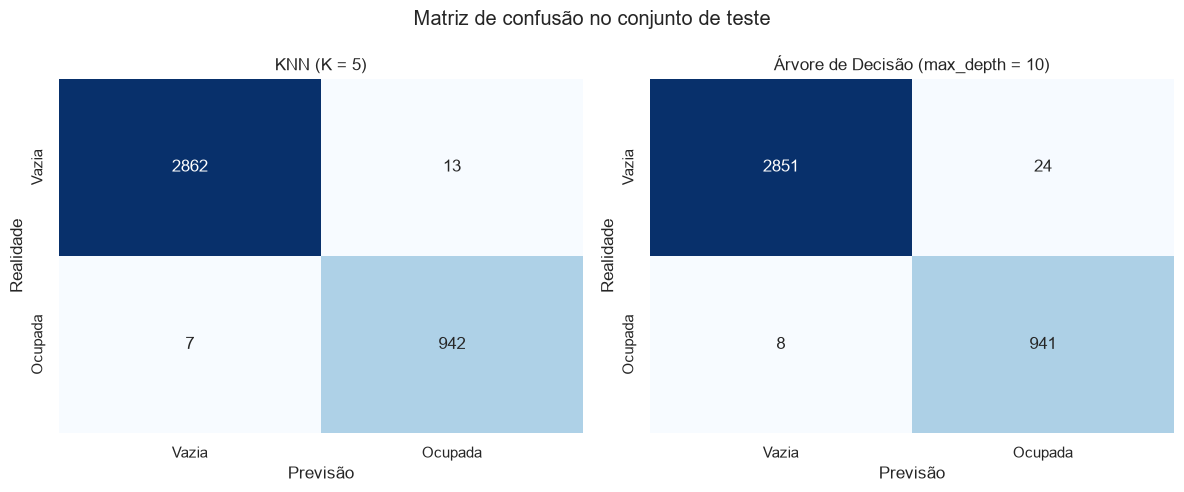

In [42]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 5))

modelos = [
    ("KNN (K = 5)", previsoes_knn),
    ("Árvore de Decisão (max_depth = 10)", previsoes_arvore)
]

for eixo, (nome, previsoes) in zip(eixos, modelos):
    matriz = confusion_matrix(y_test, previsoes)
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False, ax=eixo,
                xticklabels=["Vazia", "Ocupada"], yticklabels=["Vazia", "Ocupada"])
    eixo.set_title(nome)
    eixo.set_xlabel("Previsão")
    eixo.set_ylabel("Realidade")

plt.suptitle("Matriz de confusão no conjunto de teste")
plt.tight_layout()
plt.savefig(f"{pasta_figuras}/matriz_confusao.png", dpi=150, bbox_inches="tight")
plt.show()

**Leitura das matrizes** (linhas = realidade, colunas = previsão):

| | KNN (K = 5) | Árvore (max_depth = 10) |
|---|---|---|
| Salas vazias previstas corretamente (VN) | 2.862 | 2.851 |
| Salas ocupadas previstas corretamente (VP) | 942 | 941 |
| Falsos Positivos (FP) | 13 | 24 |
| Falsos Negativos (FN) | 7 | 8 |

- Nos **Falsos Negativos**, o erro mais grave para o sistema, os dois modelos são praticamente equivalentes: 7 no KNN e 8 na árvore, de um total de 949 medições de salas ocupadas no teste.
- A principal diferença está nos **Falsos Positivos**: a árvore cometeu **24**, quase o dobro dos **13** do KNN. Na prática, isso significa mais situações em que o ar-condicionado e a luz ficariam ligados em salas vazias, justamente o desperdício de energia que o sistema pretende evitar.

### Veredito final

**O modelo recomendado para o sistema de automação predial é o KNN com K = 5.**

**Justificativa:**

1. **Maior acurácia no teste:** 99,48%, contra 99,16% da Árvore de Decisão.
2. **Menos erros no total:** 20 erros em 3.824 medições, contra 32 da árvore.
3. **Menor desperdício de energia:** 13 Falsos Positivos, contra 24 da árvore. Como o objetivo do projeto é reduzir custos energéticos, esse é um ganho direto.
4. **Segurança equivalente para os ocupantes:** nos Falsos Negativos (desligar o sistema com pessoas na sala), os dois modelos ficaram praticamente empatados (7 contra 8).
5. **Estabilidade:** com K = 5, a diferença entre as acurácias de treino e de teste foi praticamente nula (-0,02 ponto percentual), sem sinais de overfitting.

**Pontos de atenção para a implantação:**

- O KNN depende da **padronização**: em produção, cada nova medição dos sensores precisa passar pelo mesmo `StandardScaler` ajustado no treino antes de chegar ao modelo. Por isso, o modelo e o scaler precisam ser salvos juntos, por exemplo com a biblioteca **Joblib** (Aula 3).
- A Árvore de Decisão continua sendo uma alternativa válida: com desempenho muito próximo, ela é mais fácil de interpretar (suas regras podem ser lidas como uma sequência de perguntas sobre os sensores) e não exige padronização.
- A acurácia muito alta dos dois modelos está ligada à forte relação entre luminosidade e ocupação. Vale monitorar o sistema em produção, já que mudanças no ambiente (como salas com mais luz natural) podem alterar esse padrão (*Data Drift*, Aula 2).